In [1]:
import numpy as np

rng = np.random.default_rng(42)

n_samples = len(X_train)

bootstrap_indices = rng.choice(
    n_samples,
    size=n_samples,
    replace=True,
)

X_bootstrap = X_train[bootstrap_indices]
y_bootstrap = y_train[bootstrap_indices]

print("Original training samples:", n_samples)
print("Bootstrap samples:", len(X_bootstrap))
print("Unique samples selected:", len(np.unique(bootstrap_indices)))
print("Duplicate selections:", n_samples - len(np.unique(bootstrap_indices)))

NameError: name 'X_train' is not defined

In [2]:
import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

# Load dataset
data = load_breast_cancer()

X = data.data
y = data.target

feature_names = data.feature_names
target_names = data.target_names

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (455, 30)
X_test shape: (114, 30)
y_train shape: (455,)
y_test shape: (114,)


In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1,
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred_rf))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=target_names,
    )
)

Test accuracy: 0.956140350877193

Confusion matrix:
[[39  3]
 [ 2 70]]

Classification report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [4]:
rf_oob = RandomForestClassifier(
    n_estimators=100,
    max_features="sqrt",
    oob_score=True,
    random_state=42,
    n_jobs=-1,
)

rf_oob.fit(X_train, y_train)

print("OOB accuracy:", rf_oob.oob_score_)
print("Test accuracy:", rf_oob.score(X_test, y_test))

OOB accuracy: 0.9538461538461539
Test accuracy: 0.956140350877193


## ADD MORE TREES

In [5]:
from sklearn.ensemble import RandomForestClassifier

tree_counts = [10, 25, 50, 100, 200, 400]
results = []

forest = RandomForestClassifier(
    n_estimators=10,
    max_features="sqrt",
    oob_score=True,
    warm_start=True,
    random_state=42,
    n_jobs=-1
)

for n_trees in tree_counts:
    forest.set_params(n_estimators=n_trees)
    forest.fit(X_train, y_train)

    results.append({
        "n_estimators": n_trees,
        "oob_accuracy": forest.oob_score_,
        "test_accuracy": forest.score(X_test, y_test)
    })

results_df = pd.DataFrame(results)
results_df

/home/hamid/Documents/project/MLlearn/.venv/lib/python3.12/site-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


,n_estimators,oob_accuracy,test_accuracy
0,10,0.936264,0.938596
1,25,0.947253,0.956140
2,50,0.945055,0.956140
3,100,0.953846,0.956140
4,200,0.960440,0.956140
5,400,0.960440,0.956140


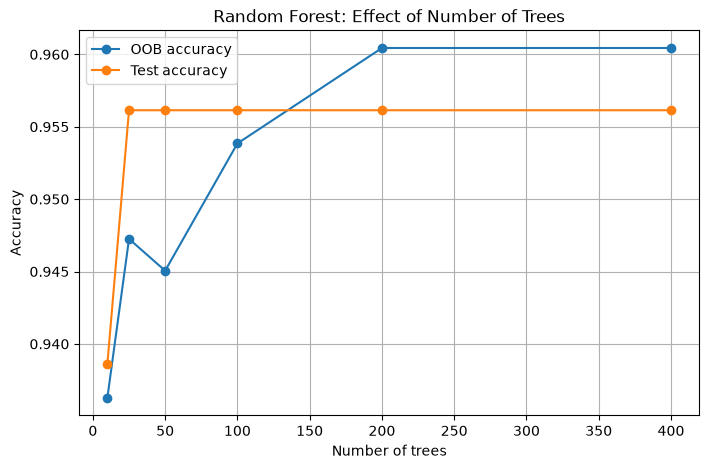

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["n_estimators"],
    results_df["oob_accuracy"],
    marker="o",
    label="OOB accuracy"
)

plt.plot(
    results_df["n_estimators"],
    results_df["test_accuracy"],
    marker="o",
    label="Test accuracy"
)

plt.xlabel("Number of trees")
plt.ylabel("Accuracy")
plt.title("Random Forest: Effect of Number of Trees")
plt.legend()
plt.grid(True)
plt.show()

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

feature_options = [1, "sqrt", None]
feature_results = []

for max_features in feature_options:
    model = RandomForestClassifier(
        n_estimators=200,
        max_features=max_features,
        random_state=42,
        n_jobs=-1
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    feature_results.append({
        "max_features": max_features,
        "cv_mean_accuracy": scores.mean(),
        "cv_std": scores.std()
    })

pd.DataFrame(feature_results)

,max_features,cv_mean_accuracy,cv_std
0,1,0.964835,0.014579
1,sqrt,0.960440,0.019160
2,None,0.958242,0.016150


In [8]:
rf_best = RandomForestClassifier(
    n_estimators=200,
    max_features=1,
    random_state=42,
    n_jobs=-1
)

rf_best.fit(X_train, y_train)

importances = pd.Series(
    rf_best.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

importances.head(10)

worst area              0.082449
worst perimeter         0.065984
mean radius             0.063325
worst radius            0.059095
mean area               0.058397
mean perimeter          0.056563
mean concavity          0.055890
worst concave points    0.045791
worst concavity         0.044912
mean concave points     0.043299
dtype: float64

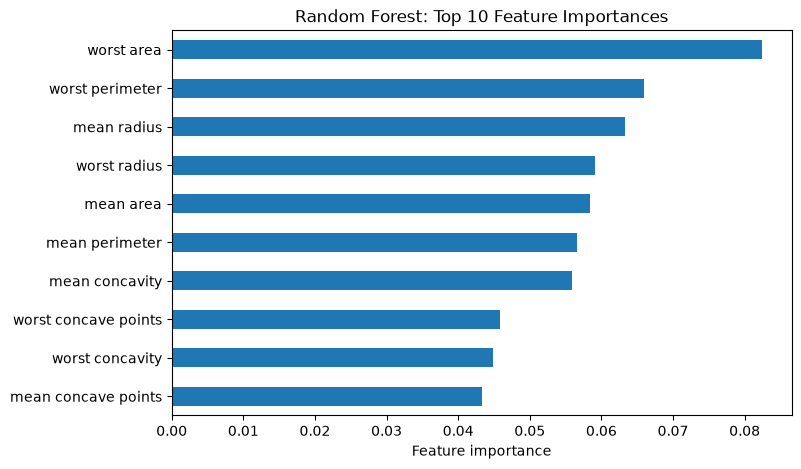

In [9]:
importances.head(10).sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.xlabel("Feature importance")
plt.title("Random Forest: Top 10 Feature Importances")
plt.show()

In [10]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    rf_best,
    X_test,
    y_test,
    scoring="accuracy",
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

perm_importances = pd.Series(
    perm_result.importances_mean,
    index=feature_names
).sort_values(ascending=False)

perm_importances.head(10)

worst concavity            0.009064
symmetry error             0.008772
worst fractal dimension    0.007602
worst symmetry             0.007018
area error                 0.005848
fractal dimension error    0.005556
mean smoothness            0.005263
worst perimeter            0.005263
worst smoothness           0.004094
mean area                  0.004094
dtype: float64

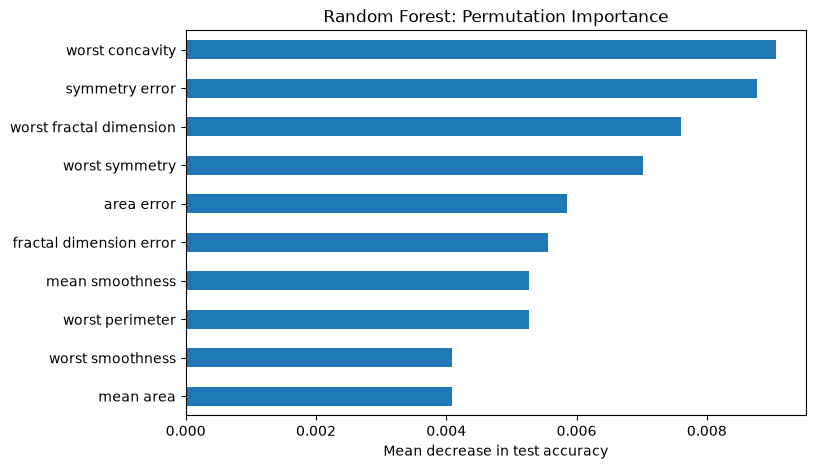

In [11]:
perm_importances.head(10).sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.xlabel("Mean decrease in test accuracy")
plt.title("Random Forest: Permutation Importance")
plt.show()

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

single_tree = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

forest_model = RandomForestClassifier(
    n_estimators=100,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

single_tree.fit(X_train, y_train)
forest_model.fit(X_train, y_train)

tree_pred = single_tree.predict(X_test)
forest_pred = forest_model.predict(X_test)

In [13]:
print("Decision Tree:", accuracy_score(y_test, tree_pred))
print("Random Forest:", accuracy_score(y_test, forest_pred))

Decision Tree: 0.9385964912280702
Random Forest: 0.956140350877193


In [14]:
print("Decision Tree:")
print(confusion_matrix(y_test, tree_pred))

print("\nRandom Forest:")
print(confusion_matrix(y_test, forest_pred))

Decision Tree:
[[39  3]
 [ 4 68]]

Random Forest:
[[39  3]
 [ 2 70]]
